# LangGraph Time Travel: Research Assistant with Query Refinement

## Overview

**Time travel** in LangGraph is a powerful feature that lets you go back to any point in an agent's execution history, modify the state, and create alternative timelines. This isn't just debugging - it's a fundamental capability for building interactive agents that can:

- Accept mid-execution guidance from users
- Explore multiple solution paths from a single starting point
- Recover from mistakes by branching from earlier states
- Create "what-if" scenarios without re-running expensive operations

Think of it like Git for agent execution: every step creates a checkpoint, and you can branch from any checkpoint to explore alternatives.

## Use Case: Research Assistant with Interactive Direction

We'll build a research assistant that:

1. **parse_request**: Takes a research question
2. **generate_queries**: LLM generates 2-3 search queries (influenced by optional `direction`)
3. **search_and_summarize**: Uses Tavily API to find information
4. **generate_report**: Synthesizes findings into a final report

After the initial run, we'll:
- Go back to before query generation
- Add a `direction` field (technical, business, historical)
- Resume execution and observe how the workflow adapts

## Learning Objectives

By the end of this tutorial, you will:

1. Understand LangGraph's checkpoint-based execution model
2. Navigate execution history using `get_state_history()`
3. Identify strategic checkpoints for time travel
4. Update state at specific checkpoints using `update_state()`
5. Resume execution from modified checkpoints
6. Create multiple alternative timelines from a single checkpoint
7. Build interactive agents that accept mid-execution guidance

## Prerequisites

**API Keys Required:**
- **OpenAI API Key**: For LLM reasoning (query generation and report synthesis)
- **Tavily API Key**: For web search functionality (https://tavily.com - free tier available)

**Required Packages:**
```bash
pip install langgraph langchain-openai langchain-core python-dotenv tavily-python
```

**Setup Instructions:**

1. Create a `.env` file in your project directory
2. Add your API keys:
   ```
   OPENAI_API_KEY=your-openai-key-here
   TAVILY_API_KEY=your-tavily-key-here
   ```

## When to Use Time Travel

**Good Use Cases:**
- Interactive agents that accept user guidance mid-execution
- Exploring multiple solution approaches without re-running setup
- A/B testing different prompts or parameters
- Debugging by replaying with modified state
- Recovery from errors by branching before the failure

**Not Ideal For:**
- Real-time applications where latency is critical
- Simple linear workflows with no branching needs
- Stateless operations that don't benefit from checkpoints

**Rule of Thumb:** Use time travel when you need to explore alternative paths or accept guidance without re-running expensive or non-deterministic operations.

## Part 1: Setup and Imports

Let's import all necessary libraries and verify our environment is correctly configured.

In [57]:
import os
import logging
from typing import TypedDict, List, Dict, Optional
from datetime import datetime

from dotenv import load_dotenv
from tavily import TavilyClient

from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

# Load environment variables
load_dotenv()

# Verify API keys are present
required_keys = ["OPENAI_API_KEY", "TAVILY_API_KEY"]
missing_keys = [key for key in required_keys if not os.getenv(key)]

if missing_keys:
    raise ValueError(f"Missing required API keys: {', '.join(missing_keys)}")

print("All required API keys loaded successfully!")
print("Libraries imported successfully!")

All required API keys loaded successfully!
Libraries imported successfully!


## Part 2: Configure Structured Logging

Logging is essential for understanding how time travel affects execution flow. We'll log:
- When each node executes
- What the current state contains
- Which checkpoint we're resuming from
- How direction influences query generation

In [58]:
# Configure logging with clear format
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',
    datefmt='%H:%M:%S'
)

# Create logger for our workflow
logger = logging.getLogger('research_workflow')

# Test the logger
logger.info("Logging system initialized")

print("Logging configured - watch for structured logs during execution")

13:54:44 - research_workflow - INFO - Logging system initialized


Logging configured - watch for structured logs during execution


## Part 3: Define State Schema

Our state needs to track the research process from question to final report.

**Key Field: `direction`**

The `direction` field is optional and acts as guidance for the LLM during query generation:
- If `None`: LLM generates general queries
- If present: LLM focuses queries on that direction (technical, business, historical, etc.)

This is the field we'll add via time travel to influence the workflow.

In [59]:
class ResearchState(TypedDict):
    """State for research assistant workflow."""
    research_question: str              # User's research question
    direction: Optional[str]            # Direction to guide query generation
    generated_queries: List[str]        # Search queries generated by LLM
    search_results: Dict[str, str]      # Query -> summary mappings
    final_report: str                   # Synthesized research report


print("State schema defined!")
print("\nState fields:")
print("  - research_question: The question to research")
print("  - direction: Optional guidance for query generation")
print("  - generated_queries: List of search queries")
print("  - search_results: Dictionary mapping queries to summaries")
print("  - final_report: Final synthesized report")

State schema defined!

State fields:
  - research_question: The question to research
  - direction: Optional guidance for query generation
  - generated_queries: List of search queries
  - search_results: Dictionary mapping queries to summaries
  - final_report: Final synthesized report


## Part 4: Initialize LLM and Tavily Client

We'll use:
- **GPT-4o**: For query generation and report synthesis (better reasoning)
- **Tavily**: For web search to find relevant information

Temperature is set low (0.1) to ensure consistent, focused outputs.

In [60]:
# Initialize LLM for query generation and report synthesis
llm = ChatOpenAI(model="gpt-4o", temperature=0.1)

# Initialize Tavily client for web search
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

print("LLM and Tavily client initialized successfully!")
print(f"  - LLM: {llm.model_name}")
print(f"  - Temperature: {llm.temperature}")
print("  - Search: Tavily API")

LLM and Tavily client initialized successfully!
  - LLM: gpt-4o
  - Temperature: 0.1
  - Search: Tavily API


## Part 5: Build Workflow Nodes

Each node performs one step of the research process.

### Node 1: parse_request_node

**Responsibility:**
- Validate the research question
- Initialize state
- Preserve `direction` if it exists

When we resume from a checkpoint after adding `direction`, this node must keep it in the state for the next node to use.

In [61]:
def parse_request_node(state: ResearchState) -> ResearchState:
    """
    Entry node: Validate research question and initialize state.
    
    Preserves 'direction' if present for time travel scenarios.
    """
    question = state.get("research_question", "").strip()
    
    if not question:
        raise ValueError("Research question cannot be empty")
    
    logger.info(f"=== Starting research for: {question} ===")
    
    direction = state.get("direction")
    if direction:
        logger.info(f"Direction guidance detected: '{direction}'")
    else:
        logger.info("No direction guidance - will generate general queries")
    
    return {
        "research_question": question,
        "direction": direction,
        "generated_queries": [],
        "search_results": {},
        "final_report": ""
    }


print("parse_request_node defined!")
print("  - Validates input")
print("  - Initializes state")
print("  - Preserves direction field for time travel")

parse_request_node defined!
  - Validates input
  - Initializes state
  - Preserves direction field for time travel


### Node 2: generate_queries_node

**Behavior:**
1. Check if `direction` exists in state
2. If present: Adjust prompt to focus queries on that direction
3. If absent: Generate general queries
4. Use LLM to generate 2-3 search queries

When we time travel back and add `direction`, this node will naturally generate different queries aligned with that direction.

In [62]:
def generate_queries_node(state: ResearchState) -> ResearchState:
    """
    Generate search queries using LLM.
    
    Adapts query generation based on 'direction' field:
    - If direction exists: Focus queries on that direction
    - If direction is None: Generate general queries
    """
    question = state["research_question"]
    direction = state.get("direction")
    
    logger.info(f"[generate_queries] Processing question: {question}")
    
    # Build prompt based on whether direction is provided
    if direction:
        logger.info(f"[generate_queries] Using direction: '{direction}'")
        prompt = f"""You are a research assistant. Generate 2-3 focused search queries to research this question.

Research Question: {question}

IMPORTANT: Focus your queries specifically on the {direction} aspects of this topic.
Your queries should help find information about {direction} related to the question.

Generate 2-3 search queries, one per line. Make them specific and focused on {direction}.

Example format:
query 1
query 2
query 3
"""
    else:
        logger.info("[generate_queries] No direction - generating general queries")
        prompt = f"""You are a research assistant. Generate 2-3 search queries to comprehensively research this question.

Research Question: {question}

Generate 2-3 diverse search queries that cover different aspects of this topic.
Make them specific and actionable, one per line.

Example format:
query 1
query 2
query 3
"""
    
    # Generate queries with LLM
    response = llm.invoke(prompt)
    queries_text = response.content.strip()
    
    # Parse queries (one per line)
    queries = [q.strip() for q in queries_text.split('\n') if q.strip()]
    
    # Keep only first 3 queries
    queries = queries[:3]
    
    logger.info(f"[generate_queries] Generated {len(queries)} queries")
    for i, q in enumerate(queries, 1):
        logger.info(f"  Query {i}: {q}")
    
    return {
        "research_question": state["research_question"],
        "direction": state.get("direction"),
        "generated_queries": queries,
        "search_results": {},
        "final_report": ""
    }


print("generate_queries_node defined!")
print("  - Checks for direction guidance")
print("  - Adapts prompt based on direction")
print("  - Generates 2-3 focused queries")

generate_queries_node defined!
  - Checks for direction guidance
  - Adapts prompt based on direction
  - Generates 2-3 focused queries


### Node 3: search_and_summarize_node

**Responsibility:**
- Execute each query using Tavily API
- Extract relevant content from search results
- Create concise summaries for each query
- Handle search failures gracefully

In [63]:
def search_and_summarize_node(state: ResearchState) -> ResearchState:
    """
    Execute searches and create summaries for each query.
    """
    queries = state["generated_queries"]
    
    logger.info(f"[search] Executing {len(queries)} searches...")
    
    search_results = {}
    
    for i, query in enumerate(queries, 1):
        logger.info(f"[search] Query {i}/{len(queries)}: {query}")
        
        try:
            # Execute search
            results = tavily_client.search(
                query=query,
                max_results=3,
                search_depth="basic"
            )
            
            if not results or 'results' not in results:
                logger.warning(f"[search] No results for query: {query}")
                search_results[query] = "No results found"
                continue
            
            # Extract and combine content from top results
            content_pieces = []
            for result in results['results'][:3]:
                if 'content' in result:
                    content_pieces.append(result['content'][:300])
            
            if content_pieces:
                combined_content = " ".join(content_pieces)
                # Truncate to reasonable length
                summary = combined_content[:500] + "..." if len(combined_content) > 500 else combined_content
                search_results[query] = summary
                logger.info(f"[search] Found {len(content_pieces)} results")
            else:
                search_results[query] = "No content extracted"
                logger.warning(f"[search] No content extracted for query: {query}")
        
        except Exception as e:
            logger.error(f"[search] Error searching '{query}': {e}")
            search_results[query] = f"Search failed: {str(e)}"
    
    logger.info(f"[search] Completed {len(search_results)} searches")
    
    return {
        "research_question": state["research_question"],
        "direction": state.get("direction"),
        "generated_queries": state["generated_queries"],
        "search_results": search_results,
        "final_report": ""
    }


print("search_and_summarize_node defined!")
print("  - Executes Tavily searches")
print("  - Extracts and summarizes content")
print("  - Handles errors gracefully")

search_and_summarize_node defined!
  - Executes Tavily searches
  - Extracts and summarizes content
  - Handles errors gracefully


### Node 4: generate_report_node

**Responsibility:**
- Synthesize all search results into a coherent report
- Mention the direction if one was provided
- Cite which queries contributed to findings
- Create a well-structured, informative report

In [64]:
def generate_report_node(state: ResearchState) -> ResearchState:
    """
    Synthesize search results into a final research report.
    """
    question = state["research_question"]
    direction = state.get("direction")
    queries = state["generated_queries"]
    search_results = state["search_results"]
    
    logger.info("[report] Synthesizing findings into final report...")
    
    # Build context from search results
    search_context = ""
    for i, (query, summary) in enumerate(search_results.items(), 1):
        search_context += f"\nQuery {i}: {query}\nFindings: {summary}\n"
    
    # Build prompt
    if direction:
        direction_note = f"\n\nIMPORTANT: This research was focused on {direction}. Make sure your report emphasizes these aspects."
    else:
        direction_note = ""
    
    prompt = f"""You are a research analyst. Synthesize the following search results into a clear, informative report.

Research Question: {question}
{direction_note}

Search Results:
{search_context}

Create a well-structured report that:
1. Directly answers the research question
2. Synthesizes information from multiple sources
3. Is clear and easy to understand
4. Is 2-3 paragraphs long
{"5. Emphasizes " + direction + " aspects" if direction else ""}

Write the report now:
"""
    
    # Generate report
    response = llm.invoke(prompt)
    report = response.content.strip()
    
    logger.info("[report] Report generated successfully")
    logger.info(f"=== Research completed for: {question} ===")
    
    return {
        "research_question": state["research_question"],
        "direction": state.get("direction"),
        "generated_queries": state["generated_queries"],
        "search_results": state["search_results"],
        "final_report": report
    }


print("generate_report_node defined!")
print("  - Synthesizes all findings")
print("  - Creates structured report")
print("  - Mentions direction if provided")

generate_report_node defined!
  - Synthesizes all findings
  - Creates structured report
  - Mentions direction if provided


## Part 6: Build Workflow Graph

Now we assemble all nodes into a linear workflow.

**Critical Component: MemorySaver**

The `MemorySaver` checkpointer is what enables time travel:
- Saves state after every node execution
- Creates a checkpoint at each step
- Allows retrieval of execution history
- Enables resuming from any checkpoint

Without a checkpointer, time travel is not possible.

In [65]:
# Create the state graph
workflow = StateGraph(ResearchState)

# Add all nodes
workflow.add_node("parse_request", parse_request_node)
workflow.add_node("generate_queries", generate_queries_node)
workflow.add_node("search_and_summarize", search_and_summarize_node)
workflow.add_node("generate_report", generate_report_node)

# Add edges (linear workflow)
workflow.add_edge(START, "parse_request")
workflow.add_edge("parse_request", "generate_queries")
workflow.add_edge("generate_queries", "search_and_summarize")
workflow.add_edge("search_and_summarize", "generate_report")
workflow.add_edge("generate_report", END)

# Use MemorySaver checkpointer to enable time travel
checkpointer = MemorySaver()
research_app = workflow.compile(checkpointer=checkpointer)

print("Workflow compiled successfully!")
print("\nWorkflow structure:")
print("  START → parse_request → generate_queries → search_and_summarize → generate_report → END")
print("\nCheckpointer: MemorySaver (enables time travel)")

Workflow compiled successfully!

Workflow structure:
  START → parse_request → generate_queries → search_and_summarize → generate_report → END

Checkpointer: MemorySaver (enables time travel)


## Part 7: Visualize Workflow

Let's create a visual representation of our research workflow.

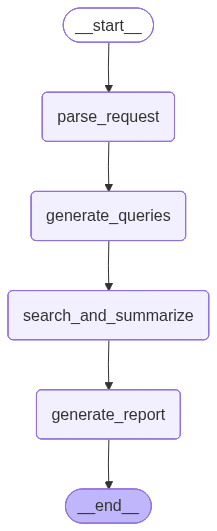

In [66]:
from IPython.display import Image, display

try:
    display(Image(research_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Could not generate graph visualization: {e}")
    print("\nWorkflow structure (text):")
    print("""
    START
      ↓
    parse_request
      ↓
    generate_queries
      ↓
    search_and_summarize
      ↓
    generate_report
      ↓
    END
    """)

## Part 8: Initial Run (No Direction)

Let's run the workflow with a research question but no direction guidance.

**What to observe:**
- The LLM generates general, broad queries
- Search finds information across various aspects
- Report covers the topic comprehensively but without specific focus

We need to use a `thread_id` in the config to track this execution and retrieve its history later.

In [67]:
print("=" * 80)
print("INITIAL RUN: Research without Direction")
print("=" * 80)
print("\nResearch Question: What are AI agents and how do they work?")
print("Direction: None (will generate general queries)\n")

# Create initial state
initial_state = {
    "research_question": "What are AI agents and how do they work?",
    "direction": None,  # No direction initially
    "generated_queries": [],
    "search_results": {},
    "final_report": ""
}

# Create config with thread_id for tracking
config = {"configurable": {"thread_id": "research_001"}}

# Run the workflow
initial_result = research_app.invoke(initial_state, config)

print("\n" + "=" * 80)
print("INITIAL RESULTS")
print("=" * 80)

print("\nGenerated Queries:")
for i, query in enumerate(initial_result["generated_queries"], 1):
    print(f"  {i}. {query}")

print("\nFinal Report:")
print(initial_result["final_report"])

print("\n" + "=" * 80)

13:54:58 - research_workflow - INFO - === Starting research for: What are AI agents and how do they work? ===
13:54:58 - research_workflow - INFO - No direction guidance - will generate general queries
13:54:58 - research_workflow - INFO - [generate_queries] Processing question: What are AI agents and how do they work?
13:54:58 - research_workflow - INFO - [generate_queries] No direction - generating general queries


INITIAL RUN: Research without Direction

Research Question: What are AI agents and how do they work?
Direction: None (will generate general queries)



13:55:01 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
13:55:01 - research_workflow - INFO - [generate_queries] Generated 3 queries
13:55:01 - research_workflow - INFO -   Query 1: 1. "Overview of AI agents: definitions and types in artificial intelligence"
13:55:01 - research_workflow - INFO -   Query 2: 2. "Mechanisms and algorithms behind the functioning of AI agents"
13:55:01 - research_workflow - INFO -   Query 3: 3. "Applications and real-world examples of AI agents in various industries"
13:55:01 - research_workflow - INFO - [search] Executing 3 searches...
13:55:01 - research_workflow - INFO - [search] Query 1/3: 1. "Overview of AI agents: definitions and types in artificial intelligence"
13:55:04 - research_workflow - INFO - [search] Found 3 results
13:55:04 - research_workflow - INFO - [search] Query 2/3: 2. "Mechanisms and algorithms behind the functioning of AI agents"
13:55:05 - research_workflow - INFO - [search] Found 3 


INITIAL RESULTS

Generated Queries:
  1. 1. "Overview of AI agents: definitions and types in artificial intelligence"
  2. 2. "Mechanisms and algorithms behind the functioning of AI agents"
  3. 3. "Applications and real-world examples of AI agents in various industries"

Final Report:
**Report on AI Agents and Their Functioning**

AI agents are autonomous entities in artificial intelligence that perceive their environment through sensors and act upon that environment using actuators to achieve specific goals. These agents can range from simple rule-based systems to complex, learning-based models. They are designed to operate independently, making decisions based on the data they receive and the objectives they are programmed to fulfill. AI agents can be categorized into several types, including reactive agents, which respond to stimuli without internal states, and cognitive agents, which possess memory and learning capabilities to adapt over time.

The functioning of AI agents relies

## Part 9: Explore Execution History

Now let's retrieve the execution history to see all the checkpoints that were created.

**What is a checkpoint?**
A checkpoint is a snapshot of the state at a specific point in execution. Each checkpoint has:
- `values`: The state at that point
- `next`: Which node(s) will execute next
- `config`: Configuration including a unique checkpoint ID
- `metadata`: Additional info (timestamp, source, etc.)

Checkpoints are returned in **reverse chronological order** (newest first).

In [68]:
print("=" * 80)
print("EXPLORING EXECUTION HISTORY")
print("=" * 80)
print("\nRetrieving all checkpoints from the initial run...\n")

# Get state history (returns a generator)
history = list(research_app.get_state_history(config))

print(f"Found {len(history)} checkpoints (in reverse chronological order)\n")

# Display each checkpoint
for i, checkpoint in enumerate(history):
    print(f"Checkpoint {i}:")
    print(f"  Next node(s): {checkpoint.next}")
    print(f"  Direction in state: {checkpoint.values.get('direction')}")
    print(f"  Has queries: {bool(checkpoint.values.get('generated_queries'))}")
    print(f"  Has search results: {bool(checkpoint.values.get('search_results'))}")
    print(f"  Has report: {bool(checkpoint.values.get('final_report'))}")
    print(f"  Checkpoint ID: {checkpoint.config['configurable']['checkpoint_id'][:8]}...")
    print()

print("=" * 80)

EXPLORING EXECUTION HISTORY

Retrieving all checkpoints from the initial run...

Found 6 checkpoints (in reverse chronological order)

Checkpoint 0:
  Next node(s): ()
  Direction in state: None
  Has queries: True
  Has search results: True
  Has report: True
  Checkpoint ID: 1f0c11e7...

Checkpoint 1:
  Next node(s): ('generate_report',)
  Direction in state: None
  Has queries: True
  Has search results: True
  Has report: False
  Checkpoint ID: 1f0c11e7...

Checkpoint 2:
  Next node(s): ('search_and_summarize',)
  Direction in state: None
  Has queries: True
  Has search results: False
  Has report: False
  Checkpoint ID: 1f0c11e7...

Checkpoint 3:
  Next node(s): ('generate_queries',)
  Direction in state: None
  Has queries: False
  Has search results: False
  Has report: False
  Checkpoint ID: 1f0c11e7...

Checkpoint 4:
  Next node(s): ('parse_request',)
  Direction in state: None
  Has queries: False
  Has search results: False
  Has report: False
  Checkpoint ID: 1f0c11e7...



## Part 10: Understanding Checkpoint Structure

Let's understand what each checkpoint represents:

| Index | Next Node(s) | Description | State |
|-------|-------------|-------------|-------|
| 0 | `()` | Workflow completed | Full state with final report |
| 1 | `('generate_report',)` | After search, before report | Has queries and search results |
| 2 | `('search_and_summarize',)` | After queries, before search | Has queries, no search results |
| 3 | `('generate_queries',)` | After parse, before query generation | No queries yet ← **Time Travel Target** |
| 4 | `('parse_request',)` | Before parse | Initial state |
| 5 | `(START,)` | Start of execution | Empty |

Checkpoint 3 is our target because:
1. The question has been validated
2. The state is initialized
3. But queries haven't been generated yet
4. We can add `direction` to influence query generation

Time traveling to checkpoint 3 lets us influence query generation without re-running parsing or re-initializing state.

## Part 11: Identify the Key Checkpoint

Let's programmatically find checkpoint 3 - the one right before query generation.

We identify it by looking for a checkpoint where:
- `next` contains only `('generate_queries',)`
- This means `parse_request` has completed
- And `generate_queries` is about to execute

In [69]:
print("=" * 80)
print("IDENTIFYING TIME TRAVEL TARGET")
print("=" * 80)
print("\nSearching for checkpoint after parse_request, before generate_queries...\n")

# Find the checkpoint where generate_queries is next
target_checkpoint = None
for i, checkpoint in enumerate(history):
    if checkpoint.next == ('generate_queries',):
        target_checkpoint = checkpoint
        print(f"Found target checkpoint at index {i}!")
        print(f"\nCheckpoint details:")
        print(f"  Next node: {checkpoint.next}")
        print(f"  Current state:")
        print(f"    - research_question: {checkpoint.values['research_question']}")
        print(f"    - direction: {checkpoint.values.get('direction')}")
        print(f"    - generated_queries: {checkpoint.values['generated_queries']}")
        print(f"    - search_results: {checkpoint.values['search_results']}")
        print(f"    - final_report: {checkpoint.values['final_report']}")
        print(f"  Checkpoint ID: {checkpoint.config['configurable']['checkpoint_id']}")
        break

if not target_checkpoint:
    raise ValueError("Could not find target checkpoint!")

print("\n" + "=" * 80)

IDENTIFYING TIME TRAVEL TARGET

Searching for checkpoint after parse_request, before generate_queries...

Found target checkpoint at index 3!

Checkpoint details:
  Next node: ('generate_queries',)
  Current state:
    - research_question: What are AI agents and how do they work?
    - direction: None
    - generated_queries: []
    - search_results: {}
    - final_report: 
  Checkpoint ID: 1f0c11e7-4116-6e4e-8001-ba238e187243



## Part 12: Interactive Direction Choice

Now let's ask the user what direction they want to explore.

**Common directions:**
- **Technical implementation details**: Focus on how AI agents work internally
- **Business applications and ROI**: Focus on practical use cases and value
- **Historical context and evolution**: Focus on how AI agents developed over time
- **Ethical considerations**: Focus on risks, bias, and responsible use
- **Comparison with alternatives**: Focus on how AI agents differ from other approaches

The direction can be any phrase that guides the LLM's focus.

In [71]:
print("=" * 80)
print("INTERACTIVE DIRECTION SELECTION")
print("=" * 80)
print("\nWe're about to time travel back and add a 'direction' to guide query generation.")
print("\nCommon direction examples:")
print("  - 'technical implementation details'")
print("  - 'business applications and ROI'")
print("  - 'historical context and evolution'")
print("  - 'ethical considerations'")
print("  - 'comparison with traditional systems'")
print("\nThe direction can be any phrase that describes the focus you want.\n")

# Get direction from user
user_direction = input("Enter your desired research direction (or press Enter for 'technical implementation details'): ").strip()

# Use default if empty
if not user_direction:
    user_direction = "technical implementation details"
    print(f"\nUsing default direction: '{user_direction}'")
else:
    print(f"\nUsing your direction: '{user_direction}'")

print("\n" + "=" * 80)

INTERACTIVE DIRECTION SELECTION

We're about to time travel back and add a 'direction' to guide query generation.

Common direction examples:
  - 'technical implementation details'
  - 'business applications and ROI'
  - 'historical context and evolution'
  - 'ethical considerations'
  - 'comparison with traditional systems'

The direction can be any phrase that describes the focus you want.



Enter your desired research direction (or press Enter for 'technical implementation details'):  business applications and roi



Using your direction: 'business applications and roi'



## Part 13: Update State with Direction (Time Travel!)

Now we'll update the state at our target checkpoint.

**What we're doing:**
1. Take the target checkpoint (before query generation)
2. Add the `direction` field to its state
3. Use `as_node="parse_request"` to specify where execution should resume from
4. Create a new checkpoint with the modified state
5. Get back a new config pointing to this checkpoint

**Understanding `as_node`:**

The `as_node` parameter tells the workflow which node "produced" this updated state:

```python
research_app.update_state(
    checkpoint.config,
    values={"direction": "..."},
    as_node="parse_request"
)
```

This ensures:
- The workflow knows to continue from after `parse_request`
- The next node (`generate_queries`) will execute with the updated state
- New queries will be generated (not reused from cache)

**Important notes:**
- This doesn't modify the original timeline
- It creates a new branch from that checkpoint
- The original execution is preserved
- You can create multiple branches from the same checkpoint

In [72]:
print("=" * 80)
print("TIME TRAVEL: Updating State at Target Checkpoint")
print("=" * 80)
print(f"\nAdding direction: '{user_direction}'")
print("\nThis will:")
print("  1. Create a NEW checkpoint with direction added")
print("  2. Branch from the original timeline")
print("  3. Keep the original execution intact")
print("  4. Tell the workflow to continue from after parse_request")
print("\nUpdating state...\n")

# Update the state at the target checkpoint
new_config = research_app.update_state(
    target_checkpoint.config,
    values={"direction": user_direction},
    as_node="parse_request"
)

print("State updated successfully!")
print(f"\nNew checkpoint created with ID: {new_config['configurable']['checkpoint_id']}")
print(f"Original checkpoint ID: {target_checkpoint.config['configurable']['checkpoint_id']}")
print("\nThese are different checkpoints - we've created a branch!")
print("\n" + "=" * 80)

TIME TRAVEL: Updating State at Target Checkpoint

Adding direction: 'business applications and roi'

This will:
  1. Create a NEW checkpoint with direction added
  2. Branch from the original timeline
  3. Keep the original execution intact
  4. Tell the workflow to continue from after parse_request

Updating state...

State updated successfully!

New checkpoint created with ID: 1f0c11e9-77d8-67fa-8002-23c78e66e86f
Original checkpoint ID: 1f0c11e7-4116-6e4e-8001-ba238e187243

These are different checkpoints - we've created a branch!



## Part 14: Resume Execution from Modified Checkpoint

Now we resume execution from the modified checkpoint.

**What happens:**
1. The workflow picks up from the checkpoint (after parse_request)
2. `generate_queries_node` sees the `direction` field
3. It adapts its prompt to focus on that direction
4. LLM generates queries aligned with the direction
5. Rest of workflow executes normally with these new queries

We pass `None` as the input state because we're resuming from a checkpoint, not starting fresh. The workflow loads state from the checkpoint automatically.

In [73]:
print("=" * 80)
print("RESUMING EXECUTION FROM MODIFIED CHECKPOINT")
print("=" * 80)
print(f"\nDirection: '{user_direction}'")
print("\nResuming workflow...\n")

# Resume execution from the modified checkpoint
# Pass None because we're resuming, not starting fresh
alternative_result = research_app.invoke(None, new_config)

print("\n" + "=" * 80)
print("ALTERNATIVE TIMELINE RESULTS")
print("=" * 80)

print(f"\nDirection: {alternative_result['direction']}")

print("\nGenerated Queries:")
for i, query in enumerate(alternative_result["generated_queries"], 1):
    print(f"  {i}. {query}")

print("\nFinal Report:")
print(alternative_result["final_report"])

print("\n" + "=" * 80)

13:56:00 - research_workflow - INFO - [generate_queries] Processing question: What are AI agents and how do they work?
13:56:00 - research_workflow - INFO - [generate_queries] Using direction: 'business applications and roi'


RESUMING EXECUTION FROM MODIFIED CHECKPOINT

Direction: 'business applications and roi'

Resuming workflow...



13:56:01 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
13:56:01 - research_workflow - INFO - [generate_queries] Generated 3 queries
13:56:01 - research_workflow - INFO -   Query 1: AI agents business applications ROI
13:56:01 - research_workflow - INFO -   Query 2: AI agents impact on business efficiency and ROI
13:56:01 - research_workflow - INFO -   Query 3: Case studies on AI agents improving business ROI
13:56:01 - research_workflow - INFO - [search] Executing 3 searches...
13:56:01 - research_workflow - INFO - [search] Query 1/3: AI agents business applications ROI
13:56:03 - research_workflow - INFO - [search] Found 3 results
13:56:03 - research_workflow - INFO - [search] Query 2/3: AI agents impact on business efficiency and ROI
13:56:05 - research_workflow - INFO - [search] Found 3 results
13:56:05 - research_workflow - INFO - [search] Query 3/3: Case studies on AI agents improving business ROI
13:56:06 - research_workflow - IN


ALTERNATIVE TIMELINE RESULTS

Direction: business applications and roi

Generated Queries:
  1. AI agents business applications ROI
  2. AI agents impact on business efficiency and ROI
  3. Case studies on AI agents improving business ROI

Final Report:
**Report on AI Agents: Business Applications and ROI**

AI agents are sophisticated software programs designed to perform tasks autonomously, often simulating human interaction and decision-making processes. In the business context, these agents are increasingly being deployed to enhance operational efficiency and drive significant returns on investment (ROI). AI agents can be integrated into various business functions, such as customer service, HR management, and supply chain optimization. For instance, they can provide real-time support to customers in banking, assist employees in navigating complex HR policies, and streamline supply chain operations. By automating routine tasks and providing intelligent insights, AI agents help busi

## Part 15: Compare Results Across Timelines

Now let's do a side-by-side comparison of the two timelines:
1. **Original timeline**: No direction, general queries
2. **Alternative timeline**: With direction, focused queries

**What to observe:**
- How queries changed based on direction
- How the final report's focus shifted

In [74]:
print("=" * 80)
print("TIMELINE COMPARISON")
print("=" * 80)
print("\n")

# Compare research questions (should be the same)
print("Research Question:")
print(f"  {initial_result['research_question']}")
print("\n")

# Compare directions
print("Direction:")
print(f"  Original:    {initial_result.get('direction') or 'None'}")
print(f"  Alternative: {alternative_result.get('direction')}")
print("\n")

print("=" * 80)

TIMELINE COMPARISON


Research Question:
  What are AI agents and how do they work?


Direction:
  Original:    None
  Alternative: business applications and roi




### Query Comparison

Let's compare the queries generated in each timeline:

In [75]:
print("GENERATED QUERIES COMPARISON")
print("=" * 80)
print("\n")

# Get the queries from both timelines
original_queries = initial_result['generated_queries']
alternative_queries = alternative_result['generated_queries']

# Display side by side
max_queries = max(len(original_queries), len(alternative_queries))

for i in range(max_queries):
    print(f"Query {i + 1}:")
    print("-" * 80)
    
    if i < len(original_queries):
        print(f"  Original (no direction):")
        print(f"    {original_queries[i]}")
    else:
        print(f"  Original (no direction): -")
    
    print()
    
    if i < len(alternative_queries):
        print(f"  Alternative (with '{user_direction}'):")
        print(f"    {alternative_queries[i]}")
    else:
        print(f"  Alternative: -")
    
    print("\n")

print("=" * 80)

GENERATED QUERIES COMPARISON


Query 1:
--------------------------------------------------------------------------------
  Original (no direction):
    1. "Overview of AI agents: definitions and types in artificial intelligence"

  Alternative (with 'business applications and roi'):
    AI agents business applications ROI


Query 2:
--------------------------------------------------------------------------------
  Original (no direction):
    2. "Mechanisms and algorithms behind the functioning of AI agents"

  Alternative (with 'business applications and roi'):
    AI agents impact on business efficiency and ROI


Query 3:
--------------------------------------------------------------------------------
  Original (no direction):
    3. "Applications and real-world examples of AI agents in various industries"

  Alternative (with 'business applications and roi'):
    Case studies on AI agents improving business ROI




### Report Comparison

Now let's compare the final reports generated from each timeline:

In [76]:
print("FINAL REPORTS COMPARISON")
print("=" * 80)
print("\n")

print("ORIGINAL TIMELINE (No Direction):")
print("-" * 80)
print(initial_result['final_report'])
print("\n" * 2)

print("ALTERNATIVE TIMELINE (With Direction: '{}'):".format(user_direction))
print("-" * 80)
print(alternative_result['final_report'])
print("\n")

print("=" * 80)

FINAL REPORTS COMPARISON


ORIGINAL TIMELINE (No Direction):
--------------------------------------------------------------------------------
**Report on AI Agents and Their Functioning**

AI agents are autonomous entities in artificial intelligence that perceive their environment through sensors and act upon that environment using actuators to achieve specific goals. These agents can range from simple rule-based systems to complex, learning-based models. They are designed to operate independently, making decisions based on the data they receive and the objectives they are programmed to fulfill. AI agents can be categorized into several types, including reactive agents, which respond to stimuli without internal states, and cognitive agents, which possess memory and learning capabilities to adapt over time.

The functioning of AI agents relies on a combination of algorithms and mechanisms that enable them to process information and make decisions. These algorithms can include decision t